In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

# IMPORTING NECESSARY LIBRARIES

# Data Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Data Pre-Processing
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Train-Test Splitting and Hyperparameter Tuning
from sklearn.model_selection import train_test_split, RandomizedSearchCV, GridSearchCV

# Models
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier

from sklearn.metrics import f1_score

/kaggle/input/competitions/workstation-rental-price-tier-prediction/kaggle_ready_dataset/sample_submission.csv
/kaggle/input/competitions/workstation-rental-price-tier-prediction/kaggle_ready_dataset/train.csv
/kaggle/input/competitions/workstation-rental-price-tier-prediction/kaggle_ready_dataset/test.csv


In [2]:
train_df = pd.read_csv("/kaggle/input/competitions/workstation-rental-price-tier-prediction/kaggle_ready_dataset/train.csv")
test_df = pd.read_csv("/kaggle/input/competitions/workstation-rental-price-tier-prediction/kaggle_ready_dataset/test.csv")

# 1. INITIAL OVERVIEW

In [3]:
train_df.head()

,space_id,operator_ref,operator_platform_age_years,operator_platform_age_months,operator_active_years,operator_active_months,operator_class,operator_certified,operator_portfolio_size,operator_has_avatar,...,score_access,score_value,compliance_status,operator_metro_units,operator_metro_whole,operator_metro_private,operator_metro_shared,reviews_per_month,metro,price_tier
0,0,Bralchu,12.0,8.0,7.0,8.0,independent_operator,f,2.0,t,...,9.12,9.54,unlicensed,2,0,2,0,0.42,MTR-09,2
1,1,Grorfian,2.0,2.0,2.0,2.0,independent_operator,f,3.0,t,...,NaN,NaN,unlicensed,3,1,2,0,NaN,MTR-01,1
2,2,Snelenr,10.0,10.0,7.0,10.0,independent_operator,f,1.0,t,...,10.00,10.00,unlicensed,1,1,0,0,0.03,MTR-01,2
3,3,Spesspe,2.0,1.0,2.0,1.0,unverified_operator,t,1.0,t,...,10.00,10.00,unlicensed,1,1,0,0,0.60,MTR-09,4
4,4,Gosho,2.0,7.0,2.0,4.0,unverified_operator,t,1.0,t,...,9.42,9.74,licensed,1,1,0,0,4.64,MTR-08,3


In [4]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 279746 entries, 0 to 279745
Data columns (total 60 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   space_id                      279746 non-null  int64  
 1   operator_ref                  279142 non-null  object 
 2   operator_platform_age_years   279142 non-null  float64
 3   operator_platform_age_months  279142 non-null  float64
 4   operator_active_years         279140 non-null  float64
 5   operator_active_months        279140 non-null  float64
 6   operator_class                279746 non-null  object 
 7   operator_certified            279142 non-null  object 
 8   operator_portfolio_size       279142 non-null  float64
 9   operator_has_avatar           279142 non-null  object 
 10  operator_id_verified          279142 non-null  object 
 11  zone                          279746 non-null  object 
 12  borough                       65295 non-null

# 2. EXPLORATORY DATA ANALYSIS

## a. Target Variable Distribution (in Percentages)

In [5]:
train_df["price_tier"].value_counts(normalize=True).sort_index().mul(100).round(2)

price_tier
1    23.91
2    29.14
3    21.75
4    25.20
Name: proportion, dtype: float64

Relatively balanced, so no need to under/over-sample (class rebalancing).

## b. Missing Values

In [6]:
drop_cols = []

In [7]:
train_df.isna().any().sum()

np.int64(30)

In [8]:
train_df.isna().any(axis = 1).sum()

np.int64(244118)

In [9]:
train_df.isna().sum().sum()

np.int64(859743)

In [10]:
# Missing count and percentage per column
missing = train_df.isna().sum()

missing_summary = (
    missing[missing > 0]
    .to_frame("missing_count")
    .assign(
        missing_pct=lambda x:
        x["missing_count"] / len(train_df) * 100
    )
    .sort_values("missing_pct", ascending=False)
)

missing_summary

,missing_count,missing_pct
borough,214451,76.659184
score_value,54246,19.391162
score_access,54245,19.390805
score_onboarding,54243,19.390090
score_accuracy,54242,19.389732
score_support,54241,19.389375
last_review_date,54240,19.389017
score_condition,54240,19.389017
first_review_date,54240,19.389017
reviews_per_month,54240,19.389017


As the column with largest missingness, borough is investigated for whether or not it is safe to drop

In [11]:
train_df.assign(borough_missing = train_df["borough"].isna()).groupby("price_tier")["borough_missing"].mean().mul(100)

price_tier
1    85.623944
2    76.485956
3    73.272079
4    71.275962
Name: borough_missing, dtype: float64

Missingness is relatively uniform across class. Hence, we may drop borough in preprocessing.

In [12]:
drop_cols.append('borough')

## c. Duplicates

In [13]:
train_df.duplicated().sum()

np.int64(0)

No duplicates are dropped. The space_id feature uniquely identifies a real-world entity (the workspace), and hence need not be dropped while checking for duplicates.

## d. Incorrect/Impossible Values

In [14]:
train_df.describe().T

,count,mean,std,min,25%,50%,75%,max
space_id,279746.0,139872.500000,8.075586e+04,0.0000,69936.2500,139872.5000,209808.7500,2.797450e+05
operator_platform_age_years,279142.0,6.794735,4.187652e+00,0.0000,3.0000,7.0000,10.0000,1.700000e+01
operator_platform_age_months,279142.0,5.453275,3.489590e+00,0.0000,2.0000,5.0000,9.0000,1.100000e+01
operator_active_years,279140.0,5.083295,4.040029e+00,0.0000,2.0000,4.0000,8.0000,1.500000e+01
operator_active_months,279140.0,5.298635,3.480848e+00,0.0000,2.0000,5.0000,8.0000,1.100000e+01
operator_portfolio_size,279142.0,49.472043,3.327522e+02,0.0000,1.0000,4.0000,19.0000,5.978000e+03
geo_lat,279746.0,77.766908,3.751376e+01,-4.8180,68.0415,94.6230,100.9410,1.117680e+02
geo_lon,279746.0,-35.144810,5.717006e+01,-123.7498,-76.5598,-31.1326,-21.2656,8.704520e+01
max_seats,279746.0,3.627312,2.277564e+00,1.0000,2.0000,3.0000,4.0000,1.600000e+01
utility_rooms,249847.0,1.358645,8.063074e-01,0.5000,1.0000,1.0000,1.5000,5.000000e+01


Many latitudes are above +90, when the range of latitude is [-90, +90].

In [15]:
len(train_df[train_df["geo_lat"].between(-90, 90)])

109378

In [16]:
invalid_lat = ~train_df["geo_lat"].between(-90, 90)

train_df.assign(invalid_lat = invalid_lat).groupby("metro")["invalid_lat"].agg(["count", "mean"]).sort_values("mean", ascending = False)

,count,mean
metro,,
MTR-02,20903,1.000000
MTR-03,10605,1.000000
MTR-04,10859,1.000000
MTR-05,7860,1.000000
MTR-08,12183,1.000000
MTR-06,12110,1.000000
MTR-11,28781,1.000000
MTR-09,35746,1.000000
MTR-13,13239,1.000000


Invalid latitude entries are associated with 9 metros FOR SURE, while to a very high degree with another.
This indicates a systematic issue pertaining to THOSE metros.
For now, we will exclude geo_lat from modelling due to its inaccuracy.

In [17]:
drop_cols.append("geo_lat")

In [18]:
cat_cols = train_df.select_dtypes(include=["object"]).columns.drop(["borough"])

for col in cat_cols:
    print(f"\n--- {col} ---")
    print("Unique values:", train_df[col].nunique())
    print(train_df[col].value_counts(dropna=False).head(10))


--- operator_ref ---
Unique values: 41903
operator_ref
Bessstu       1467
Zianovath     1160
Nalsto        1088
Dessselra     1030
Stianianlo     949
Klynfova       946
Sinnovara      801
Zelten         773
Snyniv         750
Hynbalrn       732
Name: count, dtype: int64

--- operator_class ---
Unique values: 3
operator_class
unverified_operator     127473
independent_operator    111887
managed_operator         40386
Name: count, dtype: int64

--- operator_certified ---
Unique values: 2
operator_certified
f      180235
t       98907
NaN       604
Name: count, dtype: int64

--- operator_has_avatar ---
Unique values: 2
operator_has_avatar
t      267462
f       11680
NaN       604
Name: count, dtype: int64

--- operator_id_verified ---
Unique values: 2
operator_id_verified
t      275236
f        3906
NaN       604
Name: count, dtype: int64

--- zone ---
Unique values: 1380
zone
ZN-0923    10990
ZN-0779     9377
ZN-0948     8601
ZN-0536     4658
ZN-1039     3667
ZN-0454     3621
ZN-0812   

## e. Numerical Features

### i. Summary Stats

In [19]:
train_df.describe().T

,count,mean,std,min,25%,50%,75%,max
space_id,279746.0,139872.500000,8.075586e+04,0.0000,69936.2500,139872.5000,209808.7500,2.797450e+05
operator_platform_age_years,279142.0,6.794735,4.187652e+00,0.0000,3.0000,7.0000,10.0000,1.700000e+01
operator_platform_age_months,279142.0,5.453275,3.489590e+00,0.0000,2.0000,5.0000,9.0000,1.100000e+01
operator_active_years,279140.0,5.083295,4.040029e+00,0.0000,2.0000,4.0000,8.0000,1.500000e+01
operator_active_months,279140.0,5.298635,3.480848e+00,0.0000,2.0000,5.0000,8.0000,1.100000e+01
operator_portfolio_size,279142.0,49.472043,3.327522e+02,0.0000,1.0000,4.0000,19.0000,5.978000e+03
geo_lat,279746.0,77.766908,3.751376e+01,-4.8180,68.0415,94.6230,100.9410,1.117680e+02
geo_lon,279746.0,-35.144810,5.717006e+01,-123.7498,-76.5598,-31.1326,-21.2656,8.704520e+01
max_seats,279746.0,3.627312,2.277564e+00,1.0000,2.0000,3.0000,4.0000,1.600000e+01
utility_rooms,249847.0,1.358645,8.063074e-01,0.5000,1.0000,1.0000,1.5000,5.000000e+01


The differences in ranges indicate the need for the use of a scaler.

### ii. Histograms

array([[<Axes: title={'center': 'space_id'}>,
        <Axes: title={'center': 'operator_platform_age_years'}>,
        <Axes: title={'center': 'operator_platform_age_months'}>,
        <Axes: title={'center': 'operator_active_years'}>,
        <Axes: title={'center': 'operator_active_months'}>,
        <Axes: title={'center': 'operator_portfolio_size'}>],
       [<Axes: title={'center': 'geo_lon'}>,
        <Axes: title={'center': 'max_seats'}>,
        <Axes: title={'center': 'utility_rooms'}>,
        <Axes: title={'center': 'zones'}>,
        <Axes: title={'center': 'workstations'}>,
        <Axes: title={'center': 'min_term_days'}>],
       [<Axes: title={'center': 'max_term_days'}>,
        <Axes: title={'center': 'min_term_floor'}>,
        <Axes: title={'center': 'min_term_ceiling'}>,
        <Axes: title={'center': 'max_term_floor'}>,
        <Axes: title={'center': 'max_term_ceiling'}>,
        <Axes: title={'center': 'min_term_avg'}>],
       [<Axes: title={'center': 'max_ter

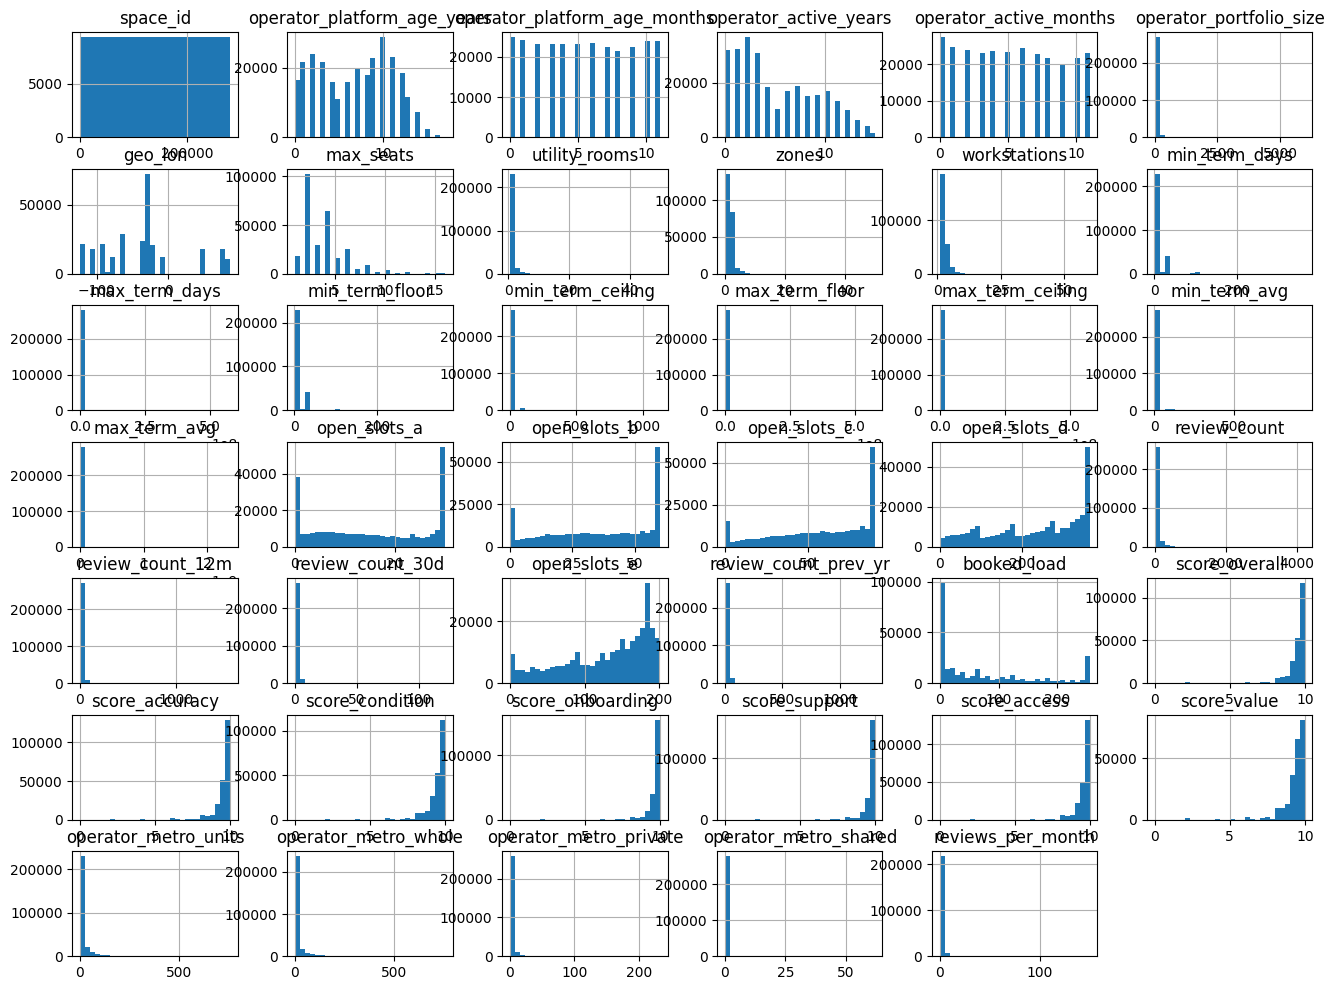

In [20]:
num_cols = train_df.select_dtypes(include = ["number"]).columns.drop(["price_tier", "geo_lat"])

train_df[num_cols].hist(figsize=(16, 12), bins=30)

Most operator-related features look approximately uniform (operator_portfolio_size and the operator_metro features are right-skewed).

Workspace specification features, such as max_seats and zones, are concentrated at small values with right-skewed distributions.

Term-day, floor, and ceiling features are concentrated at smaller values or exhibit little variation.

Open-slot features exhibit concentration at both ends of their ranges, with distributions becoming more left-skewed going from a to e.

Review-count features have relatively concentrated distributions.

Score-related features are concentrated at smaller values, with right-skewed distributions. 


Note to Self: Right-Skewed => Many values on the left side, fall down going right. And vice versa.

### iii. Outlier Handling

In [21]:
outlier_count_by_feature = {}

for feature in num_cols:
    q1 = train_df[feature].quantile(0.25)
    q3 = train_df[feature].quantile(0.75)
    iqr = q3 - q1

    lower_criteria = (train_df[feature] < (q1 - 1.5 * iqr))
    upper_criteria = (train_df[feature] > (q3 + 1.5 * iqr))
    outliers = (train_df.loc[lower_criteria | upper_criteria])

    outlier_count_by_feature[feature] = len(outliers)

outlier_summary = pd.DataFrame({
    "feature": num_cols,
    "outlier_count": [outlier_count_by_feature[f] for f in num_cols]
})

outlier_summary["outlier_pct"] = (outlier_summary["outlier_count"] / len(train_df) * 100)

outlier_summary = outlier_summary.sort_values("outlier_pct", ascending = False).reset_index(drop=True)

outlier_summary.round({"outlier_pct": 2})

,feature,outlier_count,outlier_pct
0,min_term_ceiling,57708,20.63
1,min_term_avg,57207,20.45
2,min_term_floor,53091,18.98
3,min_term_days,53091,18.98
4,operator_metro_private,49759,17.79
5,operator_metro_whole,44953,16.07
6,operator_metro_units,40157,14.35
7,operator_portfolio_size,39784,14.22
8,review_count_30d,38748,13.85
9,geo_lon,29033,10.38


In [22]:
drop_cols

['borough', 'geo_lat']

## f. Categorical Features

In [23]:
cat_summary = pd.DataFrame({
    "unique_values": train_df[cat_cols].nunique(),
    "missing_count": train_df[cat_cols].isna().sum()
})

cat_summary.sort_values("unique_values", ascending = False)

,unique_values,missing_count
facilities,251649,0
operator_ref,41903,604
first_review_date,5342,54240
last_review_date,3287,54240
zone,1380,0
snapshot_end_date,384,0
snapshot_start_date,383,0
space_class,131,0
metro,16,0
access_type,4,0


facilities is a list of "FCL-xxx" -> Multi-Hot Encode
Low-cardinality (<= 16) -> OneHot
Higher-cardinality -> Require further investigation on best method.

## g. Numerical Feature-to-Feature and Feature-to-Target Relationships

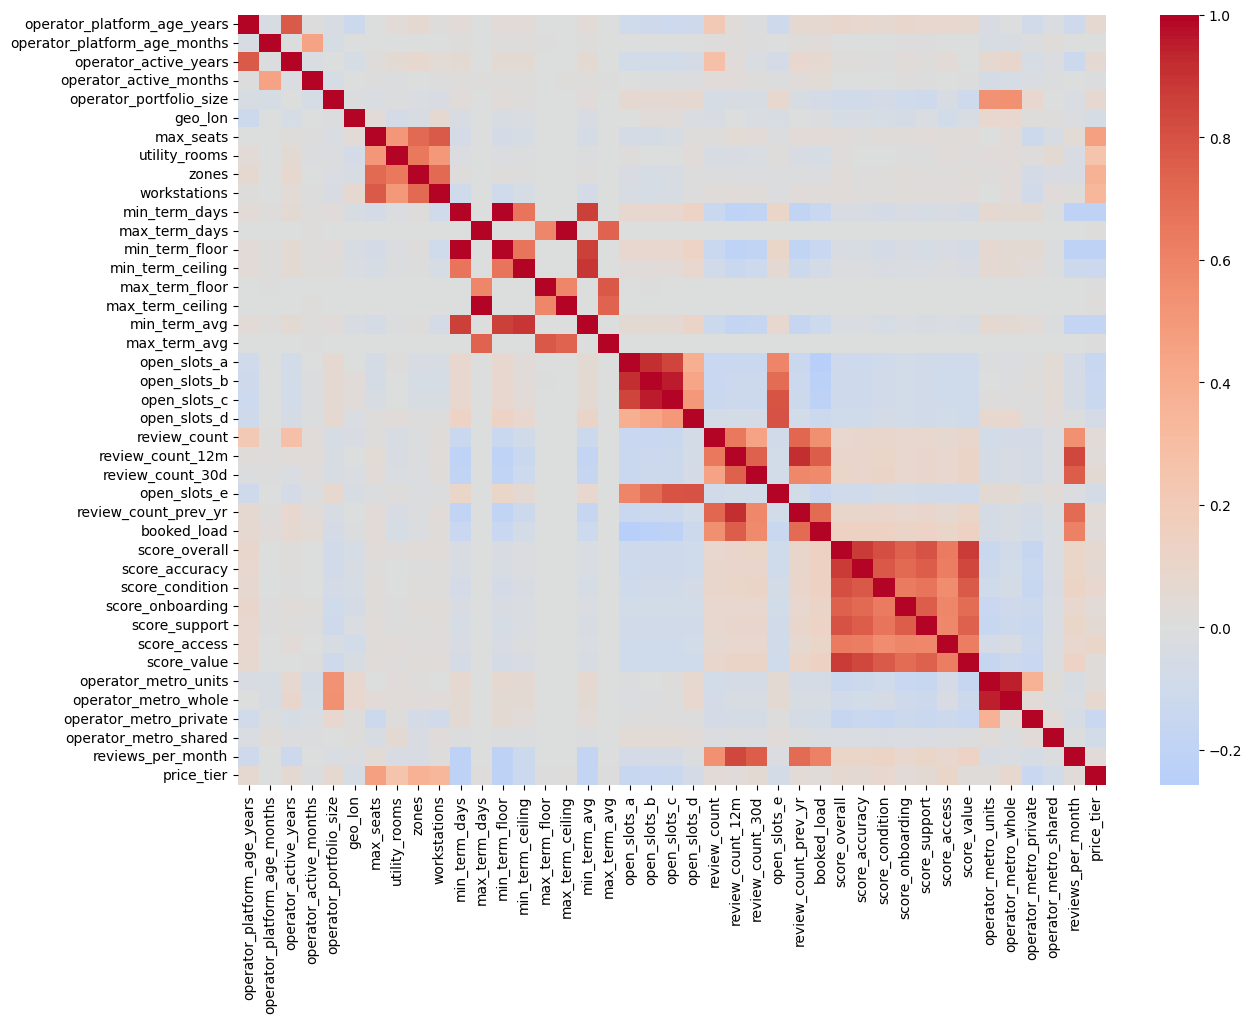

In [24]:
import seaborn as sns
import matplotlib.pyplot as plt

corr_cols = train_df.select_dtypes(include="number").columns.drop(
    ["space_id", "geo_lat"], errors = "ignore"
)

plt.figure(figsize=(14, 10))
sns.heatmap(train_df[corr_cols].corr(), cmap = "coolwarm", center=0)
plt.show()

max_seats, zones, utility_rooms, workstations -> Strong feature to target.

max_seats, utility_rooms, zones, and workstations are positively correlated.
min_term and max_term features are positively correlated within their groups.
open_slots features are strongly correlated.

Review counts are strongly correlated. 
Score features are strongly correlated.
operator_metro features are strongly correlated, though to varying degrees.

All of these are strong, positive correlations.

## h. Categorical Feature-to-Target Relationships

<Axes: xlabel='space_class'>

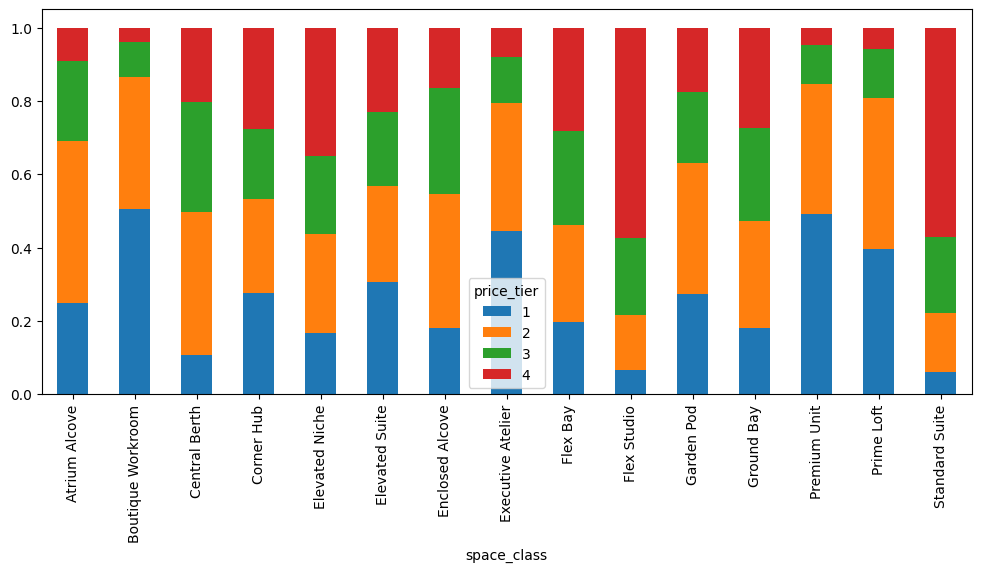

In [25]:
# 15 most freq space_classes

top_classes = train_df["space_class"].value_counts().head(15).index

subset = train_df[train_df["space_class"].isin(top_classes)]

pd.crosstab(
    subset["space_class"],
    subset["price_tier"],
    normalize = "index"
).plot(kind = "bar", stacked = True, figsize = (12, 5))

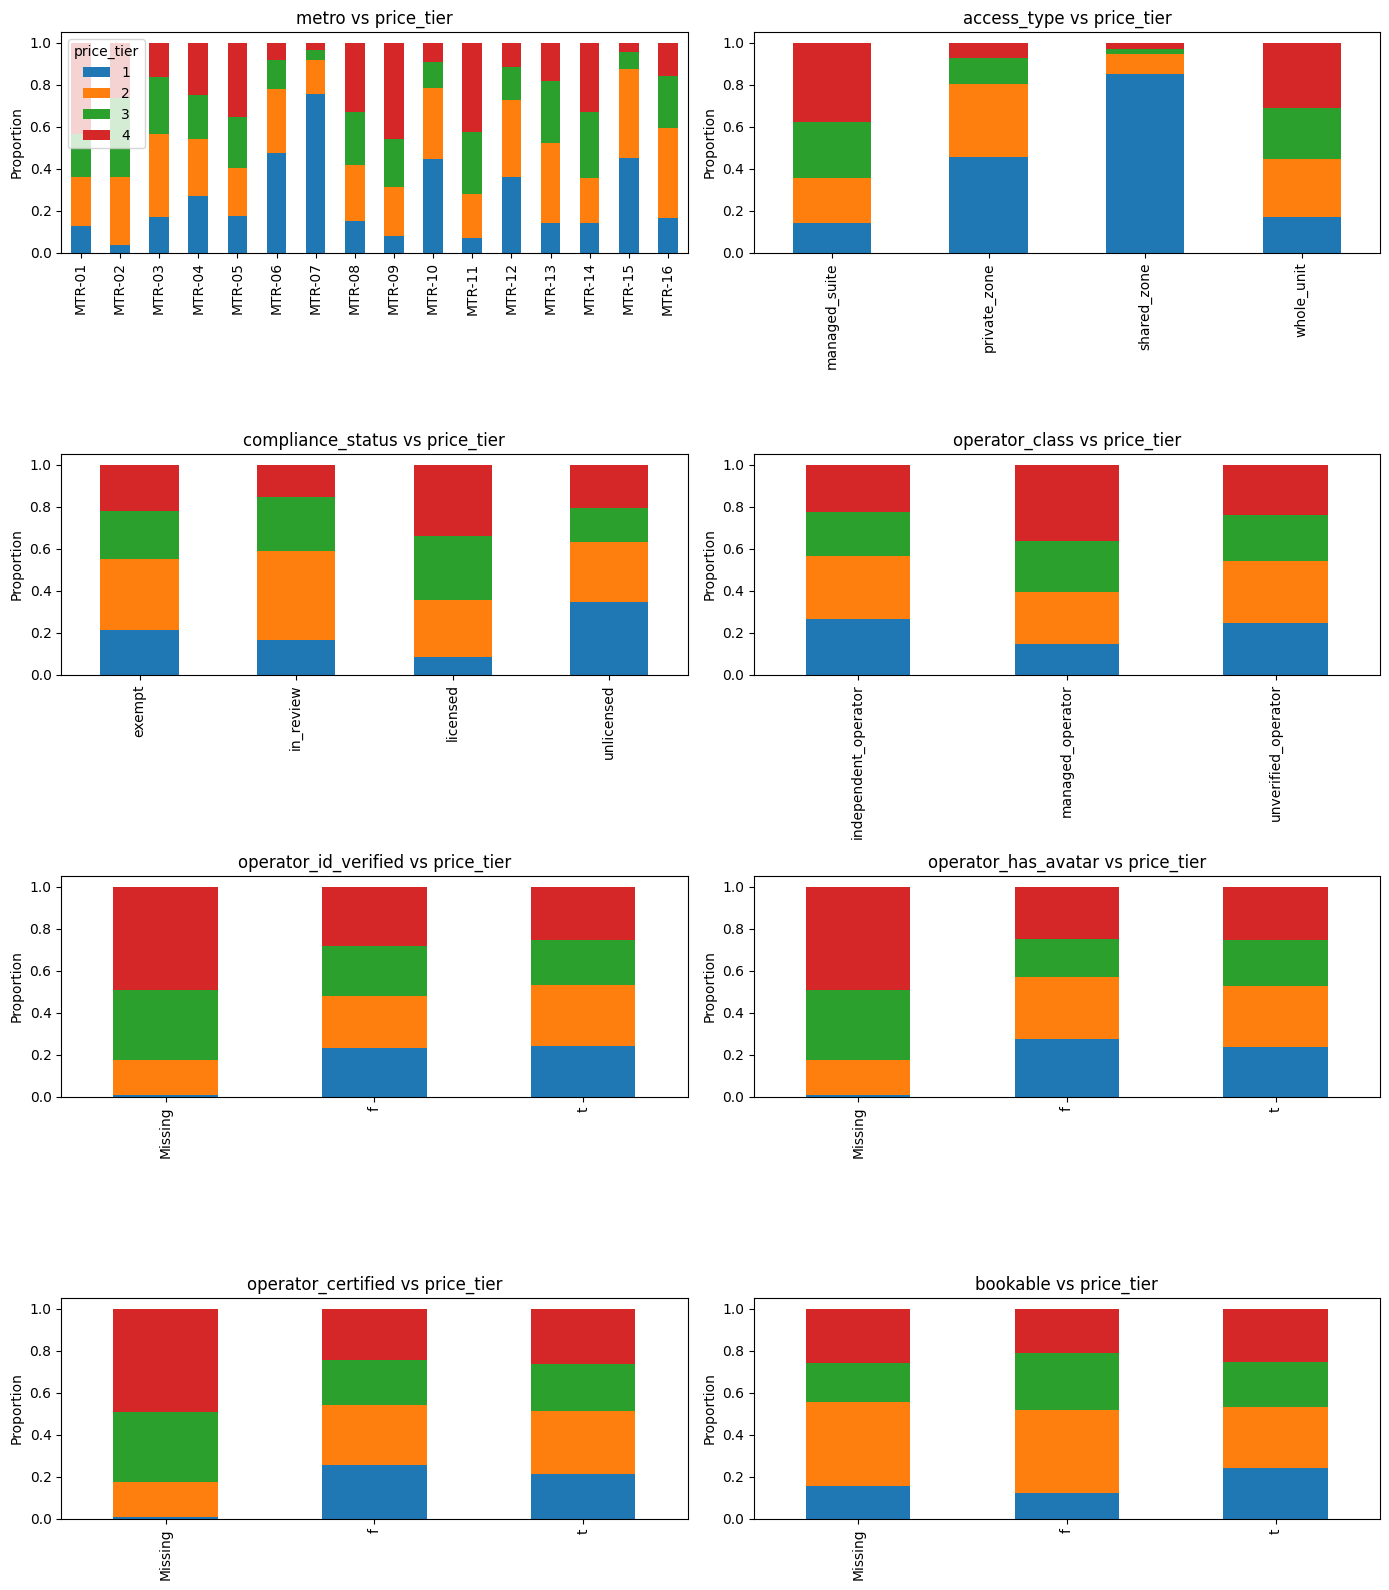

In [26]:
cat_cols = ["metro", "access_type", "compliance_status", "operator_class", 
        "operator_id_verified", "operator_has_avatar", "operator_certified", "bookable"
]

fig, axes = plt.subplots(4, 2, figsize=(14, 16))
axes = axes.flatten()

for i, col in enumerate(cat_cols):
    pd.crosstab(train_df[col].fillna("Missing"), train_df["price_tier"], normalize = "index"
    ).plot(kind="bar", stacked = True, ax = axes[i], legend = (i == 0))

    axes[i].set_title(f"{col} vs price_tier")
    axes[i].set_ylabel("Proportion")
    axes[i].set_xlabel("")

for j in range(len(cat_cols), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

 metro, access_type, operator_class, compliance_status are useful features

In [27]:
# space_id is an irrelevant column here
# operator_ref is also irrelevant for the most part.
drop_cols.extend(['space_id', 'operator_ref'])

X = train_df.drop(columns = ["price_tier"] + drop_cols, errors = "ignore")
y = train_df["price_tier"]

X_test = test_df.drop(columns=drop_cols, errors = "ignore")

# 3. PRE-PROCESSING

In [28]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size = 0.2, random_state = 42, stratify = y)

## FEATURE ENGINEERING AND SELECTION

## a. Handling facilities

In [29]:
for df in [X_train, X_val, X_test]:
    # 1. Remove duplicates inside each list (keeps original order)
    df["facilities"] = df["facilities"].apply(lambda x: list(dict.fromkeys(x)) if isinstance(x, list) else x)
    
    # 2. Get the accurate, deduplicated count
    df["facility_count"] = df["facilities"].apply(len)

    df.drop(columns = ["facilities"], inplace = True)

In [30]:
X_train['facility_count']

90461     407
197948    231
66974     176
91378     363
60760     451
         ... 
177589    385
127515    484
27808     418
65295     110
38721     451
Name: facility_count, Length: 223796, dtype: int64

## b. Handling Date Columns

In [31]:
date_cols = ["snapshot_start_date", "snapshot_end_date", "first_review_date", "last_review_date"]

for df in [X_train, X_val, X_test]:
    for col in date_cols:
        df[col] = pd.to_datetime(df[col], errors = "coerce")

    df["snapshot_interval_days"] = (df["snapshot_end_date"] - df["snapshot_start_date"]).dt.days
    df["review_interval_days"] = (df["last_review_date"] - df["first_review_date"]).dt.days

    df.drop(columns=date_cols, inplace=True)

## c. Group-based Feature Engineering

In [32]:
# Count categories using training data only
class_counts = X_train["space_class"].fillna("Missing").value_counts()

zone_counts = X_train["zone"].astype("string").fillna("Missing").value_counts()

metro_counts = X_train["metro"].astype("string").fillna("Missing").value_counts()

# Map counts onto all datasets
for df in [X_train, X_val, X_test]:
    df["class_count"] = df["space_class"].fillna("Missing").map(class_counts).fillna(0)
    df["zone_count"] = df["zone"].astype("string").fillna("Missing").map(zone_counts).fillna(0)
    df["metro_count"] = df["metro"].astype("string").fillna("Missing").map(metro_counts).fillna(0)

## PIPELINE

## a. Imputation


- Categorical features will have missing values imputed using the most_frequent strategy.
- Numerical features will have missing values imputed using the median strategy.

In [33]:
num_cols = X_train.select_dtypes(include = "number").columns.tolist()
cat_cols = X_train.select_dtypes(include = ["object", "category"]).columns.tolist()

In [34]:
imputer = ColumnTransformer(transformers = [
                            ("categoricalImputer", SimpleImputer(strategy = "most_frequent"), cat_cols),
                            ("numericalImputer", SimpleImputer(strategy = "median"), num_cols)
                            ], remainder = 'passthrough', verbose_feature_names_out = False
                           ).set_output(transform = 'pandas')

## b. Scaling Numerical Features

- Numerical features are scaled using the StandardScaler

In [35]:
scaler = ColumnTransformer(transformers = [
                            ("standardScaler", StandardScaler(), num_cols)
                            ], remainder = 'passthrough', verbose_feature_names_out = False
                          ).set_output(transform = 'pandas')

## c. Encoding Categorical Features

- operator_ref is dropped
- Other columns are OneHotEncoded

In [36]:
encoder = ColumnTransformer(transformers = [
                            ("oneHot", OneHotEncoder(drop = 'first', sparse_output = False, handle_unknown = 'ignore'), cat_cols)
                            ], remainder = 'passthrough', verbose_feature_names_out = False
                           ).set_output(transform = 'pandas')

In [37]:
pre_pipeline = Pipeline(steps = [
    ("Imputation", imputer), ("Encoding", encoder), ("Scaling", scaler)
]).set_output(transform = 'pandas')

pre_pipeline

Pipeline(steps=[('Imputation',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('categoricalImputer',
                                                  SimpleImputer(strategy='most_frequent'),
                                                  ['operator_class',
                                                   'operator_certified',
                                                   'operator_has_avatar',
                                                   'operator_id_verified',
                                                   'zone', 'space_class',
                                                   'access_type', 'bookable',
                                                   'compliance_status',
                                                   'metro']),
                                                 ('numericalImputer',
                                                  SimpleImputer(strategy...
                                                   'max_term_days',
                                                   'min_term_floor',
                                                   'min_term_ceiling',
                                                   'max_term_floor',
                                                   'max_term_ceiling',
                                                   'min_term_avg',
                                                   'max_term_avg',
                                                   'open_slots_a',
                                                   'open_slots_b',
                                                   'open_slots_c',
                                                   'open_slots_d',
                                                   'review_count',
                                                   'review_count_12m',
                                                   'review_count_30d',
                                                   'open_slots_e',
                                                   'review_count_prev_yr',
                                                   'booked_load',
                                                   'score_overall',
                                                   'score_accuracy', ...])],
                                   verbose_feature_names_out=False))])

In [38]:
# Interaction features between max_seats and space_class encoded columns.

def add_capacity_interactions(X):
    space_class_cols = [c for c in X.columns if c.startswith("space_class_")]

    interactions = pd.DataFrame(
        X["max_seats"].to_numpy()[:, None] * X[space_class_cols].to_numpy(),
        columns = [f"max_seats_x_{c}" for c in space_class_cols],
        index = X.index
    )

    return pd.concat([X, interactions], axis=1)

# 4. MODEL TRAINING

In [39]:
X_train_processed = pre_pipeline.fit_transform(X_train)
X_val_processed = pre_pipeline.transform(X_val)
X_test_processed = pre_pipeline.transform(X_test)

/usr/local/lib/python3.12/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [4, 5] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [4, 5] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


In [40]:
X_train_inter = add_capacity_interactions(X_train_processed)
X_val_inter = add_capacity_interactions(X_val_processed)
X_test_inter = add_capacity_interactions(X_test_processed)

## Feature Selection via RFE

In [41]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score
from sklearn.feature_selection import RFE

# RFE: remove 20% of the remaining features at each iteration
rfe = RFE(estimator = RandomForestClassifier(n_estimators = 30, 
                                           random_state = 42, 
                                           class_weight = "balanced", 
                                           n_jobs = -1
                                          ),
          n_features_to_select = 500,
          step = 0.2
         )

rfe.fit(X_train_inter, y_train)
selected_features = X_train_inter.columns[rfe.support_]

# Applying the selection to training and validation data
X_train_rfe = X_train_inter[selected_features]
X_val_rfe = X_val_inter[selected_features]
X_test_rfe = X_test_inter[selected_features]

In [42]:
logistic_model = LogisticRegression(max_iter = 200)
logistic_model.fit(X_train_rfe, y_train)
logistic_pred = logistic_model.predict(X_val_rfe)
logistic_score = f1_score(y_val, logistic_pred, average="macro")

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [43]:
logistic_score

0.6504439296446871

In [44]:
# RF Model
rf_model = RandomForestClassifier(random_state = 42,class_weight = "balanced")
rf_model.fit(X_train_rfe, y_train)

rf_pred = rf_model.predict(X_val_rfe)
rf_score = f1_score(y_val, rf_pred, average="macro")

In [45]:
rf_score

0.7085563144529993

In [49]:
# MLP Model
mlp_model = MLPClassifier(
        hidden_layer_sizes=(64,),
        activation="relu",
        solver="adam",
        batch_size=1024,
        max_iter=30,
        early_stopping=True,
        n_iter_no_change=5,
        random_state=42,
        verbose=True
)

mlp_model.fit(X_train_rfe, y_train)

mlp_pred = mlp_model.predict(X_val_rfe)
mlp_score = f1_score(y_val, mlp_pred, average = "macro")

Iteration 1, loss = 0.96819754
Validation score: 0.650045
Iteration 2, loss = 0.78636081
Validation score: 0.665460
Iteration 3, loss = 0.75253260
Validation score: 0.672520
Iteration 4, loss = 0.73495892
Validation score: 0.678329
Iteration 5, loss = 0.72339173
Validation score: 0.679669
Iteration 6, loss = 0.71480151
Validation score: 0.682797
Iteration 7, loss = 0.70795574
Validation score: 0.683378
Iteration 8, loss = 0.70257830
Validation score: 0.683870
Iteration 9, loss = 0.69786281
Validation score: 0.685791
Iteration 10, loss = 0.69357339
Validation score: 0.686953
Iteration 11, loss = 0.68979200
Validation score: 0.689634
Iteration 12, loss = 0.68662002
Validation score: 0.689187
Iteration 13, loss = 0.68349514
Validation score: 0.689544
Iteration 14, loss = 0.68123787
Validation score: 0.689812
Iteration 15, loss = 0.67817828
Validation score: 0.691555
Iteration 16, loss = 0.67575212
Validation score: 0.690170
Iteration 17, loss = 0.67380147
Validation score: 0.691421
Iterat

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (30) reached and the optimization hasn't converged yet.
  warnings.warn(


In [50]:
mlp_score

0.6918752000843045

# 5. HYPERPARAMETER TUNING

# 6. FINAL SUBMISSION

In [ ]:
submission = pd.DataFrame({"ID": range(X_test.shape[0]),
                           "price_tier": y_pred})

submission.to_csv("submission.csv", index = False)